# Diabetes Hospital Readmission: Full Analysis

**Dataset:** UCI *Diabetes 130-US Hospitals for Years 1999-2008*. `diabetic_data.csv` has one row per hospital encounter, `IDS_mapping.csv` holds the lookup tables for the ID columns.

**Question:** which patients are readmitted within 30 days, and what can we predict?

This is one notebook in five parts. Run it top to bottom. Everything is imported and loaded once in **Setup**, and each part reuses the variables from the part before it (nothing is read back from disk).

| Part | What it does | Main variables |
|------|--------------|----------------|
| Setup | imports, paths, load all files | `df_raw`, lookup tables |
| 1. Exploration | look at the raw data, no changes | `df_raw` |
| 2. Cleaning | clean, build features, encode, scale | `df` (readable), `model_df` (encoded + scaled) |
| 3. EDA | charts, group rates, hypothesis tests | `df` |
| 4. Modeling | logistic regression and decision tree | `results`, `top_features` |
| 5. Dashboard prep | tidy CSVs for Power BI | `../data/powerbi/` |

The cleaned and model files are still saved to `../data/` because Power BI and `../docs/cleaning_log.md` refer to them.

## Setup

### Imports

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, ttest_ind
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, roc_auc_score,
                             confusion_matrix, roc_curve, classification_report)

DATA_DIR = "../data"
os.makedirs(f"{DATA_DIR}/powerbi", exist_ok=True)   # output folder for Part 5

### Load all data

`IDS_mapping.csv` is **three lookup tables stacked in one file**, so besides the stacked view (`mapping`, only used in Part 1) we read each table once here with `skiprows` / `nrows`. Part 2 and Part 5 use these three.

In [ ]:
# main dataset: one row per hospital encounter (raw, never changed)
df_raw = pd.read_csv(f"{DATA_DIR}/diabetic_data.csv")

# the mapping file as one stacked table (only to look at it in Part 1)
mapping = pd.read_csv(f"{DATA_DIR}/IDS_mapping.csv")

# the same file split into its 3 lookup tables
admission_type_map = pd.read_csv(f"{DATA_DIR}/IDS_mapping.csv", nrows=8)
discharge_map = pd.read_csv(f"{DATA_DIR}/IDS_mapping.csv", skiprows=10, nrows=30)
admission_source_map = pd.read_csv(f"{DATA_DIR}/IDS_mapping.csv", skiprows=42)

print("diabetic_data:", df_raw.shape)
print("lookup tables:", admission_type_map.shape, discharge_map.shape, admission_source_map.shape)

## Part 1: Data Exploration

Only *look* at the data (`df_raw`). No cleaning yet, that is Part 2.

**Steps:**
1. First look
2. Shape and data types
3. `"?"` placeholders
4. Missing values per column
5. Summary statistics
6. Encounters vs patients
7. Class balance of `readmitted`
8. Look at the ID mapping file

### Step 1: First Look

In [1]:
df_raw.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


### Step 2: Shape and Data Types

In [2]:
df_raw.shape   # (rows, columns)

(101766, 50)

In [3]:
df_raw.info()   # data type + non-null count of every column

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

In [4]:
# how many columns of each data type
df_raw.dtypes.value_counts()

object    37
int64     13
Name: count, dtype: int64

**What we see:** 101,766 encounters and 50 columns. 13 columns are numbers (`int64`) and 37 are text (`object`).

Some "numbers" are really categories in disguise: `admission_type_id`, `discharge_disposition_id` and `admission_source_id` are codes that only make sense with `IDS_mapping.csv`.

### Step 3: `"?"` Placeholders

This dataset does **not** use empty cells for unknown values. It writes a question mark `"?"` instead. Pandas does not know `"?"` means missing, so `isna()` will not find it. We count it ourselves.

In [5]:
# count "?" in every column
question_marks = (df_raw == "?").sum()

# keep only the columns that have at least one "?"
question_marks[question_marks > 0].sort_values(ascending=False)

weight               98569
medical_specialty    49949
payer_code           40256
race                  2273
diag_3                1423
diag_2                 358
diag_1                  21
dtype: int64

In [6]:
# same thing as a percentage of all rows
question_pct = ((df_raw == "?").mean() * 100).round(2)
question_pct[question_pct > 0].sort_values(ascending=False)

weight               96.86
medical_specialty    49.08
payer_code           39.56
race                  2.23
diag_3                1.40
diag_2                0.35
diag_1                0.02
dtype: float64

### Step 4: Missing Values per Column

First the "real" missing values (`NaN`) that pandas already detects.

In [7]:
# NaN count per column (only columns that have some)
nan_count = df_raw.isna().sum()
nan_count[nan_count > 0]

max_glu_serum    96420
A1Cresult        84748
dtype: int64

**Why do `max_glu_serum` and `A1Cresult` show NaN?** In the file these cells contain the word `None`, which means *the test was not done*. Pandas reads the text `None` as missing by default. So this is not lost data, it is "test not taken". We will keep that in mind in the cleaning step.

In [8]:
# a temporary copy where "?" is also treated as missing (only for counting, df_raw is not changed)
df_check = df_raw.replace("?", np.nan)

# total missing % per column, worst first
missing_pct = (df_check.isna().mean() * 100).round(2)
missing_pct = missing_pct[missing_pct > 0].sort_values(ascending=False)
missing_pct

weight               96.86
max_glu_serum        94.75
A1Cresult            83.28
medical_specialty    49.08
payer_code           39.56
race                  2.23
diag_3                1.40
diag_2                0.35
diag_1                0.02
dtype: float64

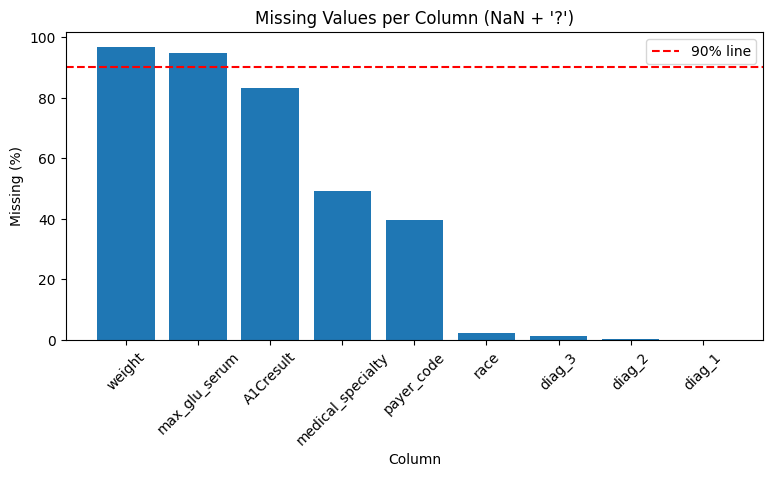

In [9]:
# bar chart of missing % per column
plt.figure(figsize=(9, 4))
plt.bar(missing_pct.index, missing_pct.values)
plt.axhline(90, color="red", linestyle="--", label="90% line")
plt.title("Missing Values per Column (NaN + '?')")
plt.xlabel("Column")
plt.ylabel("Missing (%)")
plt.xticks(rotation=45)
plt.legend()
plt.show()

In [10]:
# gender has its own placeholder value
df_raw["gender"].value_counts()

gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64

**What we see:**
- `weight` (96.86%) and `max_glu_serum` (94.75%) are above the 90% line.
- `A1Cresult` (83.28%), `medical_specialty` (49.08%) and `payer_code` (39.56%) are heavily missing too.
- `race` and the three diagnosis columns have only a small amount missing.
- `gender` has 3 rows marked `Unknown/Invalid`, another placeholder.

### Step 5: Summary Statistics

In [11]:
# numeric columns
df_raw.describe()

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.026403e+08,3.869636e+07,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.252200e+04,1.350000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,8.496119e+07,2.341322e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.523890e+08,4.550514e+07,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,2.302709e+08,8.754595e+07,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,4.438672e+08,1.895026e+08,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


In [12]:
# text columns: count, number of unique values, most common value and its frequency
df_raw.describe(include="object")

,race,gender,age,weight,payer_code,medical_specialty,diag_1,diag_2,diag_3,max_glu_serum,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
count,101766,101766,101766,101766,101766,101766,101766,101766,101766,5346,...,101766,101766,101766,101766,101766,101766,101766,101766,101766,101766
unique,6,3,10,10,18,73,717,749,790,3,...,1,4,4,2,2,2,2,2,2,3
top,Caucasian,Female,[70-80),?,?,?,428,276,250,Norm,...,No,No,No,No,No,No,No,No,Yes,NO
freq,76099,54708,26068,98569,40256,49949,6862,6752,11555,2597,...,101766,47383,101060,101753,101765,101764,101765,54755,78363,54864


**What to notice:**
- `encounter_id` and `patient_nbr` are IDs. Their mean and std mean nothing.
- `examide` and `citoglipton` have only **1 unique value**, so they carry no information.
- Count columns like `number_outpatient`, `number_emergency` and `number_inpatient` have a max far above the 75% value. That means a few extreme values (outliers), which we handle with IQR in Part 2 (Step 9).

### Step 6: Encounters vs Patients

One patient can come to the hospital many times. If the same patient appears many times, the rows are not independent.

In [13]:
print("Rows (encounters):", len(df_raw))
print("Unique encounter_id:", df_raw["encounter_id"].nunique())
print("Unique patients:", df_raw["patient_nbr"].nunique())
print("Fully duplicated rows:", df_raw.duplicated().sum())

Rows (encounters): 101766
Unique encounter_id: 101766
Unique patients: 71518
Fully duplicated rows: 0


In [14]:
# how many encounters each patient has
visits_per_patient = df_raw["patient_nbr"].value_counts()
visits_per_patient.describe()

count    71518.000000
mean         1.422942
std          1.090740
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         40.000000
Name: count, dtype: float64

**What we see:** 101,766 encounters belong to only 71,518 patients, so many patients appear more than once. There are no fully duplicated rows. In the cleaning step we keep one encounter per patient.

### Step 7: Class Balance of `readmitted`

`readmitted` has 3 values: `NO`, `>30` (readmitted after 30 days) and `<30` (readmitted within 30 days).

Our question is about **early readmission**, so we compare `<30` against everything else.

In [15]:
# the 3 original classes
df_raw["readmitted"].value_counts()

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

In [16]:
# same as percentage
(df_raw["readmitted"].value_counts(normalize=True) * 100).round(2)

readmitted
NO     53.91
>30    34.93
<30    11.16
Name: proportion, dtype: float64

In [17]:
# binary target: 1 = readmitted within 30 days, 0 = the rest (NO or >30)
df_raw["readmitted_30"] = (df_raw["readmitted"] == "<30").astype(int)

df_raw["readmitted_30"].value_counts()

readmitted_30
0    90409
1    11357
Name: count, dtype: int64

In [18]:
# percentage of each class
(df_raw["readmitted_30"].value_counts(normalize=True) * 100).round(2)

readmitted_30
0    88.84
1    11.16
Name: proportion, dtype: float64

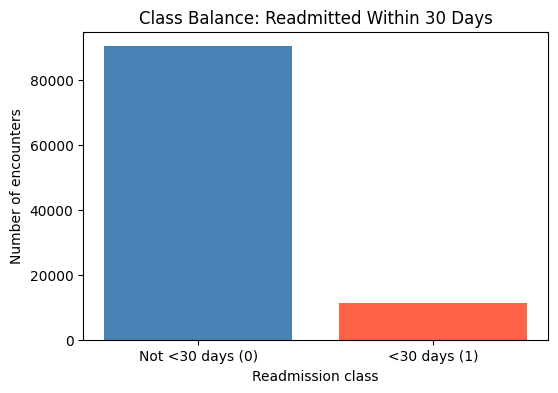

In [19]:
# bar chart of the binary target
counts = df_raw["readmitted_30"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(["Not <30 days (0)", "<30 days (1)"], counts.values, color=["steelblue", "tomato"])
plt.title("Class Balance: Readmitted Within 30 Days")
plt.xlabel("Readmission class")
plt.ylabel("Number of encounters")
plt.show()

**What we see:** only 11,357 encounters (11.16%) were readmitted within 30 days, and 90,409 (88.84%) were not. The classes are **imbalanced** (about 1 to 8). A model could reach ~89% accuracy by always guessing "not readmitted", so in modeling we must handle the imbalance and look at recall and ROC-AUC, not only accuracy.

### Step 8: Look at the ID Mapping File

`IDS_mapping.csv` is not one table. It is **three lookup tables stacked on top of each other**, separated by blank lines:
`admission_type_id`, `discharge_disposition_id`, `admission_source_id`.

In [20]:
# the mapping file read as one table just to look at it (loaded in Setup)
print(mapping.shape)
mapping.head(12)

(67, 2)


,admission_type_id,description
0,1,Emergency
1,2,Urgent
2,3,Elective
3,4,Newborn
4,5,Not Available
5,6,NaN
6,7,Trauma Center
7,8,Not Mapped
8,NaN,NaN
9,discharge_disposition_id,description


In [21]:
# rows where the first column is a header word show where each new table starts
mapping.loc[mapping["admission_type_id"].isin(["discharge_disposition_id", "admission_source_id"])]

,admission_type_id,description
9,discharge_disposition_id,description
41,admission_source_id,description


We will split this file into its three tables when we need the descriptions, for example to find the *Expired* and *Hospice* discharge codes in the cleaning step.

### Summary of Exploration

| Check | Result |
|-------|--------|
| Shape | 101,766 rows x 50 columns |
| Data types | 13 numeric, 37 text |
| `"?"` placeholders | 7 columns: `weight`, `medical_specialty`, `payer_code`, `race`, `diag_3`, `diag_2`, `diag_1` |
| Over 90% missing | `weight` (96.86%), `max_glu_serum` (94.75%, `None` = test not done) |
| Other placeholder | `gender` = `Unknown/Invalid` in 3 rows |
| Duplicated rows | 0 |
| Patients | 71,518 unique patients for 101,766 encounters |
| Target `<30` | 11,357 (11.16%) vs 90,409 (88.84%), imbalanced |

**Next:** Part 2 cleans these problems.

## Part 2: Data Cleaning

**Input:** `df_raw` (we clean a copy, the raw table stays as it is)  
**Output:**
- `df`: cleaned, real units and labels. Used for EDA (Part 3) and Power BI (Part 5). Saved as `cleaned_readable.csv`
- `model_df`: encoded and scaled, used for modeling (Part 4). Saved as `cleaned.csv`

Every decision is also written in `../docs/cleaning_log.md`.

**Steps:**
1. Start from the raw data
2. Replace `"?"` with NaN
3. Drop columns with more than 90% missing
4. Drop columns with only one value
5. Fill the remaining missing values
6. Keep one encounter per patient
7. Remove expired and hospice discharges
8. Remove invalid gender rows
9. Treat outliers with IQR
10. Group ICD-9 codes into diagnosis categories
11. Group rare medical specialties
12. Create new features
13. Create the target
14. Save the readable file
15. Encode categorical columns
16. Scale numeric columns
17. Save `cleaned.csv`

### Step 1: Start from the Raw Data

In [22]:
# work on a copy; the exploration target column is rebuilt in Step 13
df = df_raw.drop(columns=["readmitted_30"]).copy()

print("Starting shape:", df.shape)

Starting shape: (101766, 50)


### Step 2: Replace `"?"` with NaN

This file uses `"?"` for unknown values. We turn them into real `NaN` so pandas can count and fill them.

In [23]:
df = df.replace("?", np.nan)

# check: no "?" left anywhere
print('"?" left:', (df == "?").sum().sum())

"?" left: 0


### Step 3: Drop Columns with More Than 90% Missing

In [24]:
# missing % per column
missing_pct = (df.isna().mean() * 100).round(2)
missing_pct[missing_pct > 0].sort_values(ascending=False)

weight               96.86
max_glu_serum        94.75
A1Cresult            83.28
medical_specialty    49.08
payer_code           39.56
race                  2.23
diag_3                1.40
diag_2                0.35
diag_1                0.02
dtype: float64

In [25]:
# columns above the 90% line
cols_over_90 = missing_pct[missing_pct > 90].index.tolist()
print("Dropping:", cols_over_90)

df = df.drop(columns=cols_over_90)
print("Shape now:", df.shape)

Dropping: ['weight', 'max_glu_serum']
Shape now: (101766, 48)


`weight` is almost never recorded. `max_glu_serum` is missing because the test was usually not done. With less than 10% of rows filled, neither column can tell us much.

### Step 4: Drop Columns with Only One Value

A column where every row has the same value cannot help explain readmission.

In [26]:
# number of unique values per column, smallest first
df.nunique().sort_values().head(5)

examide          1
citoglipton      1
acetohexamide    2
tolbutamide      2
diabetesMed      2
dtype: int64

In [27]:
single_value_cols = df.columns[df.nunique() == 1].tolist()
print("Dropping:", single_value_cols)

df = df.drop(columns=single_value_cols)
print("Shape now:", df.shape)

Dropping: ['examide', 'citoglipton']
Shape now: (101766, 46)


### Step 5: Fill the Remaining Missing Values

| Column | Missing | Decision |
|--------|---------|----------|
| `A1Cresult` | ~83% | Fill with `"Not tested"`. Missing here means the test was not done, which is real information |
| `medical_specialty` | ~49% | Fill with `"Unknown"`. Too many missing to guess, too useful to drop |
| `payer_code` | ~40% | Fill with `"Unknown"` |
| `race` | ~2% | Fill with `"Unknown"`. We should not guess a person's race |
| `diag_1/2/3` | < 2% | Left for now. They become `"Other"` when we group the codes in Step 10 |

In [28]:
df["A1Cresult"] = df["A1Cresult"].fillna("Not tested")
df["medical_specialty"] = df["medical_specialty"].fillna("Unknown")
df["payer_code"] = df["payer_code"].fillna("Unknown")
df["race"] = df["race"].fillna("Unknown")

# what is still missing (only the diagnosis columns should be left)
df.isna().sum()[df.isna().sum() > 0]

diag_1      21
diag_2     358
diag_3    1423
dtype: int64

### Step 6: Keep One Encounter per Patient

Many patients appear several times. Their rows are not independent, and a model could "remember" a patient. We keep only the **first** encounter of each patient (smallest `encounter_id`), the same choice made in the original study of this dataset.

In [29]:
print("Rows before:", len(df))
print("Unique patients:", df["patient_nbr"].nunique())

# sort so the earliest encounter comes first, then keep the first row of each patient
df = df.sort_values("encounter_id")
df = df.drop_duplicates(subset="patient_nbr", keep="first")

print("Rows after:", len(df))

Rows before: 101766
Unique patients: 71518
Rows after: 71518


### Step 7: Remove Expired and Hospice Discharges

A patient who died or went to hospice care **cannot be readmitted**. Keeping them would wrongly teach the model that these patients are "safe".

Codes from `IDS_mapping.csv`: 11 = Expired, 13 = Hospice / home, 14 = Hospice / medical facility, 19 / 20 / 21 = Expired (at home / medical facility / place unknown).

In [30]:
# the discharge lookup table was loaded in Setup (discharge_map)
expired_hospice_ids = [11, 13, 14, 19, 20, 21]
discharge_map.loc[discharge_map["discharge_disposition_id"].isin(expired_hospice_ids)]

,discharge_disposition_id,description
10,11,Expired
12,13,Hospice / home
13,14,Hospice / medical facility
18,19,"Expired at home. Medicaid only, hospice."
19,20,"Expired in a medical facility. Medicaid only, ..."
20,21,"Expired, place unknown. Medicaid only, hospice."


In [31]:
print("Rows to remove:", df["discharge_disposition_id"].isin(expired_hospice_ids).sum())

# keep only rows whose discharge code is NOT in the list (~ means NOT)
df = df.loc[~df["discharge_disposition_id"].isin(expired_hospice_ids)]

print("Rows after:", len(df))

Rows to remove: 1545
Rows after: 69973


### Step 8: Remove Invalid Gender Rows

In [32]:
print(df["gender"].value_counts())

df = df.loc[df["gender"] != "Unknown/Invalid"]

print("Rows after:", len(df))

gender
Female             37229
Male               32741
Unknown/Invalid        3
Name: count, dtype: int64
Rows after: 69970


### Step 9: Treat Outliers with IQR

IQR rule: a value is an outlier if it is above `Q3 + 1.5 * IQR`.

We **cap** outliers (pull them down to the upper limit) instead of deleting rows, so no patient is lost.

Two rules for this dataset:
- **Only the upper side is capped.** For every column except `number_diagnoses` the lower limit is 0 or below, so nothing is flagged. For `number_diagnoses` the lower limit is 1.5, which would flag patients with only 1 diagnosis. That is a real, valid value.
- **Columns with IQR = 0 are skipped.** `number_outpatient`, `number_emergency` and `number_inpatient` have Q1 = Q3 = 0, so the upper limit would be 0 and *every* patient with a past visit would be turned into 0. That would destroy the most important information.

In [33]:
numeric_cols = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
                "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]

# look at the IQR limits of each column before changing anything
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    upper = Q3 + 1.5 * IQR
    print(col, "| Q1:", Q1, "| Q3:", Q3, "| IQR:", IQR, "| upper:", upper, "| above upper:", (df[col] > upper).sum())

time_in_hospital | Q1: 2.0 | Q3: 6.0 | IQR: 4.0 | upper: 12.0 | above upper: 1403
num_lab_procedures | Q1: 31.0 | Q3: 57.0 | IQR: 26.0 | upper: 96.0 | above upper: 98
num_procedures | Q1: 0.0 | Q3: 2.0 | IQR: 2.0 | upper: 5.0 | above upper: 3845
num_medications | Q1: 10.0 | Q3: 20.0 | IQR: 10.0 | upper: 35.0 | above upper: 1867
number_outpatient | Q1: 0.0 | Q3: 0.0 | IQR: 0.0 | upper: 0.0 | above upper: 9119
number_emergency | Q1: 0.0 | Q3: 0.0 | IQR: 0.0 | upper: 0.0 | above upper: 5100
number_inpatient | Q1: 0.0 | Q3: 0.0 | IQR: 0.0 | upper: 0.0 | above upper: 8191
number_diagnoses | Q1: 6.0 | Q3: 9.0 | IQR: 3.0 | upper: 13.5 | above upper: 42


In [34]:
# make the columns float first, because an upper limit like 13.5 is not a whole number
df[numeric_cols] = df[numeric_cols].astype(float)

# cap only the columns where IQR is bigger than 0
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    upper = Q3 + 1.5 * IQR

    if IQR == 0:
        print("Skipped (IQR = 0):", col)
    else:
        n_capped = (df[col] > upper).sum()
        df.loc[df[col] > upper, col] = upper
        print("Capped", col, "at", upper, "->", n_capped, "rows")

Capped time_in_hospital at 12.0 -> 1403 rows
Capped num_lab_procedures at 96.0 -> 98 rows
Capped num_procedures at 5.0 -> 3845 rows
Capped num_medications at 35.0 -> 1867 rows
Skipped (IQR = 0): number_outpatient
Skipped (IQR = 0): number_emergency
Skipped (IQR = 0): number_inpatient
Capped number_diagnoses at 13.5 -> 42 rows


In [35]:
# check the new maximums
df[numeric_cols].describe().loc[["min", "max"]]

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
min,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
max,12.0,96.0,5.0,35.0,42.0,42.0,12.0,13.5


### Step 10: Group ICD-9 Codes into Diagnosis Categories

`diag_1`, `diag_2` and `diag_3` hold ~700-800 different ICD-9 codes each. That is far too many categories to use directly. We group them into 9 categories using the ICD-9 chapters (the same grouping as the original study, Strack et al. 2014):

| Group | ICD-9 codes |
|-------|-------------|
| Circulatory | 390-459, 785 |
| Respiratory | 460-519, 786 |
| Digestive | 520-579, 787 |
| Diabetes | 250.xx |
| Injury | 800-999 |
| Musculoskeletal | 710-739 |
| Genitourinary | 580-629, 788 |
| Neoplasms | 140-239 |
| Other | everything else, codes starting with V or E, and missing codes |

In [36]:
# turn one ICD-9 code into its group name
def icd9_group(code):
    # missing code
    if pd.isna(code):
        return "Other"
    # V and E codes are supplementary codes, not diseases
    if code.startswith("V") or code.startswith("E"):
        return "Other"
    # diabetes codes are 250.xx
    if code.startswith("250"):
        return "Diabetes"

    num = float(code)
    if (390 <= num < 460) or int(num) == 785:
        return "Circulatory"
    if (460 <= num < 520) or int(num) == 786:
        return "Respiratory"
    if (520 <= num < 580) or int(num) == 787:
        return "Digestive"
    if 800 <= num < 1000:
        return "Injury"
    if 710 <= num < 740:
        return "Musculoskeletal"
    if (580 <= num < 630) or int(num) == 788:
        return "Genitourinary"
    if 140 <= num < 240:
        return "Neoplasms"
    return "Other"

In [37]:
# apply the function to the 3 diagnosis columns -> 3 new group columns
df["diag_1_group"] = df["diag_1"].apply(icd9_group)
df["diag_2_group"] = df["diag_2"].apply(icd9_group)
df["diag_3_group"] = df["diag_3"].apply(icd9_group)

# the raw codes are no longer needed
df = df.drop(columns=["diag_1", "diag_2", "diag_3"])

df["diag_1_group"].value_counts()

diag_1_group
Circulatory        21383
Other              12132
Respiratory         9486
Digestive           6487
Diabetes            5748
Injury              4692
Musculoskeletal     4064
Genitourinary       3440
Neoplasms           2538
Name: count, dtype: int64

### Step 11: Group Rare Medical Specialties

`medical_specialty` has 70+ values and most of them are rare. We keep the 10 most common (not counting `Unknown`) and put the rest into `"Other"`.

In [38]:
print("Unique specialties before:", df["medical_specialty"].nunique())

# the 10 most common real specialties
top_10 = df.loc[df["medical_specialty"] != "Unknown", "medical_specialty"].value_counts().head(10).index.tolist()
print("Kept:", top_10)

# everything not in the top 10 and not Unknown becomes Other
df.loc[~df["medical_specialty"].isin(top_10 + ["Unknown"]), "medical_specialty"] = "Other"

print("Unique specialties after:", df["medical_specialty"].nunique())

Unique specialties before: 71
Kept: ['InternalMedicine', 'Family/GeneralPractice', 'Emergency/Trauma', 'Cardiology', 'Surgery-General', 'Orthopedics', 'Orthopedics-Reconstructive', 'Radiologist', 'Nephrology', 'Pulmonology']
Unique specialties after: 12


### Step 12: Create New Features

| New feature | How | Why |
|-------------|-----|-----|
| `total_visits` | outpatient + emergency + inpatient visits | one number for how much hospital care the patient needed in the past year |
| `age_mid` | middle of the age band, e.g. `[70-80)` -> 75 | turns the text band into a number we can scale and test |
| `num_active_meds` | number of the diabetes medicines the patient is taking (not `No`) | how complex the treatment is |
| `num_med_changes` | number of medicines whose dose went `Up` or `Down` | how much the treatment was changed during the stay |

In [39]:
# 1. total visits in the year before this stay
df["total_visits"] = df["number_outpatient"] + df["number_emergency"] + df["number_inpatient"]

# 2. age band -> middle number: "[70-80)" -> take "70" -> 70 + 5 = 75
df["age_mid"] = df["age"].str[1:].str.split("-").str[0].astype(int) + 5

# the medicine columns: everything between A1Cresult and change in the table
med_cols = df.loc[:, "metformin":"metformin-pioglitazone"].columns.tolist()
print(len(med_cols), "medicine columns:", med_cols)

21 medicine columns: ['metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']


In [40]:
# 3. how many medicines are being taken (value is not "No")
df["num_active_meds"] = (df[med_cols] != "No").sum(axis=1)

# 4. how many medicines had their dose changed (Up or Down)
df["num_med_changes"] = df[med_cols].isin(["Up", "Down"]).sum(axis=1)

df[["age", "age_mid", "total_visits", "num_active_meds", "num_med_changes"]].head()

,age,age_mid,total_visits,num_active_meds,num_med_changes
8,[80-90),85,0.0,2,0
9,[90-100),95,0.0,2,0
4,[40-50),45,0.0,2,0
10,[40-50),45,0.0,1,0
5,[50-60),55,0.0,1,0


In [41]:
df[["total_visits", "age_mid", "num_active_meds", "num_med_changes"]].describe()

,total_visits,age_mid,num_active_meds,num_med_changes
count,69970.000000,69970.000000,69970.000000,69970.000000
mean,0.559726,65.440046,1.190124,0.261884
std,1.427786,15.974203,0.942529,0.475849
min,0.000000,5.000000,0.000000,0.000000
25%,0.000000,55.000000,1.000000,0.000000
50%,0.000000,65.000000,1.000000,0.000000
75%,1.000000,75.000000,2.000000,0.000000
max,49.000000,95.000000,6.000000,4.000000


### Step 13: Create the Target

1 = readmitted within 30 days (`<30`), 0 = not readmitted or readmitted after 30 days.

In [42]:
df["readmitted_30"] = (df["readmitted"] == "<30").astype(int)

print(df["readmitted_30"].value_counts())
print((df["readmitted_30"].value_counts(normalize=True) * 100).round(2))

readmitted_30
0    63693
1     6277
Name: count, dtype: int64
readmitted_30
0    91.03
1     8.97
Name: proportion, dtype: float64


### Step 14: Save the Readable File

Before encoding and scaling we save a copy with real units (days, ages) and text labels. EDA and Power BI need this version, because a scaled value like `-0.43` days cannot be explained to a reader.

In [43]:
# fresh row numbers (rows were sorted and dropped above)
df = df.reset_index(drop=True)

# final check: no missing values
print("Missing values:", df.isna().sum().sum())
print("Shape:", df.shape)

df.to_csv(f"{DATA_DIR}/cleaned_readable.csv", index=False)
print("Saved ../data/cleaned_readable.csv")

Missing values: 0
Shape: (69970, 51)


Saved ../data/cleaned_readable.csv


### Step 15: Encode Categorical Columns

| Type | Columns | Method |
|------|---------|--------|
| Yes / No columns | `gender`, `change`, `diabetesMed` | **label encoding** to 0 / 1 |
| Medicine columns (21) | `metformin` ... | 0 = not taken, 1 = taken (`Steady`, `Up` or `Down`). Up / Down is already counted in `num_med_changes` |
| Categories with no order | `race`, `payer_code`, `medical_specialty`, `A1Cresult`, the 3 diagnosis groups, admission type, discharge, admission source | **one-hot encoding** (`drop_first=True` removes one column per group to avoid duplicate information) |

The ID columns, the text `age` (replaced by `age_mid`) and the text `readmitted` (replaced by `readmitted_30`) are dropped.

In [44]:
# start from a copy so the readable df stays as it is
model_df = df.copy()

# drop IDs and columns that were replaced by new ones
model_df = model_df.drop(columns=["encounter_id", "patient_nbr", "age", "readmitted"])

# label encoding for the 2-value columns
model_df["gender"] = (model_df["gender"] == "Male").astype(int)        # 1 = Male, 0 = Female
model_df["change"] = (model_df["change"] == "Ch").astype(int)          # 1 = medicine changed
model_df["diabetesMed"] = (model_df["diabetesMed"] == "Yes").astype(int)  # 1 = on diabetes medicine

# medicine columns: 1 = taking it, 0 = not
for col in med_cols:
    model_df[col] = (model_df[col] != "No").astype(int)

model_df[["gender", "change", "diabetesMed", "metformin", "insulin"]].head()

,gender,change,diabetesMed,metformin,insulin
8,0,1,1,0,1
9,0,1,1,0,1
4,1,1,1,0,1
10,0,0,1,0,1
5,1,0,1,0,1


In [45]:
# ID codes are numbers but mean categories -> turn them into text first so get_dummies treats them as categories
for col in ["admission_type_id", "discharge_disposition_id", "admission_source_id"]:
    model_df[col] = model_df[col].astype(str)

one_hot_cols = ["race", "payer_code", "medical_specialty", "A1Cresult",
                "diag_1_group", "diag_2_group", "diag_3_group",
                "admission_type_id", "discharge_disposition_id", "admission_source_id"]

model_df = pd.get_dummies(model_df, columns=one_hot_cols, drop_first=True, dtype=int)

print("Shape after encoding:", model_df.shape)

Shape after encoding: (69970, 140)


### Step 16: Scale Numeric Columns

Numeric columns have very different ranges (e.g. `num_lab_procedures` up to 96, `num_procedures` up to 5). Logistic regression works better when they are on the same scale. `StandardScaler` changes each column to mean 0 and standard deviation 1.

The 0/1 columns and the target are **not** scaled.

In [46]:
scale_cols = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
              "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses",
              "total_visits", "age_mid", "num_active_meds", "num_med_changes"]

scaler = StandardScaler()
model_df[scale_cols] = scaler.fit_transform(model_df[scale_cols])

# check: mean should be ~0 and std ~1
model_df[scale_cols].describe().loc[["mean", "std"]].round(2)

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,total_visits,age_mid,num_active_meds,num_med_changes
mean,-0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.0,0.0,-0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


### Step 17: Save `cleaned.csv`

In [47]:
print("Missing values:", model_df.isna().sum().sum())
print("Final shape:", model_df.shape)
print("Target rate (%):", round(model_df["readmitted_30"].mean() * 100, 2))

model_df.to_csv(f"{DATA_DIR}/cleaned.csv", index=False)
print("Saved ../data/cleaned.csv")

Missing values: 0
Final shape: (69970, 140)
Target rate (%): 8.97


Saved ../data/cleaned.csv


### Summary

| Stage | Rows |
|-------|------|
| Raw data | 101,766 |
| One encounter per patient | 71,518 |
| Expired / hospice removed | 69,973 |
| Invalid gender removed | **69,970** |

See `../docs/cleaning_log.md` for every decision and its reason.

## Part 3: Exploratory Data Analysis

**Input:** `df` from Part 2 (69,970 patients, one encounter each, real units)

**Steps:**
1. Start from the cleaned data
2. Descriptive statistics
3. Distributions (histograms)
4. Readmission rate by key groups
5. Relationships between variables (scatter and pair plot)
6. Correlation heatmap
7. Hypothesis tests
8. Key insights

### Step 1: Start from the Cleaned Data

In [48]:
# overall readmission rate, used as a reference line in the charts
overall_rate = df["readmitted_30"].mean() * 100

print("Shape:", df.shape)
print("Overall 30-day readmission rate:", round(overall_rate, 2), "%")

Shape: (69970, 51)
Overall 30-day readmission rate: 8.97 %


### Step 2: Descriptive Statistics

In [49]:
numeric_cols = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
                "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses",
                "total_visits", "age_mid", "num_active_meds", "num_med_changes"]

# count, mean, std, min, quartiles, max of every numeric column
df[numeric_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
time_in_hospital,69970.0,4.24,2.85,1.0,2.0,3.0,6.0,12.0
num_lab_procedures,69970.0,42.87,19.87,1.0,31.0,44.0,57.0,96.0
num_procedures,69970.0,1.37,1.62,0.0,0.0,1.0,2.0,5.0
num_medications,69970.0,15.43,7.47,1.0,10.0,14.0,20.0,35.0
number_outpatient,69970.0,0.28,1.06,0.0,0.0,0.0,0.0,42.0
number_emergency,69970.0,0.10,0.51,0.0,0.0,0.0,0.0,42.0
number_inpatient,69970.0,0.18,0.60,0.0,0.0,0.0,0.0,12.0
number_diagnoses,69970.0,7.22,2.00,1.0,6.0,8.0,9.0,13.5
total_visits,69970.0,0.56,1.43,0.0,0.0,0.0,1.0,49.0
age_mid,69970.0,65.44,15.97,5.0,55.0,65.0,75.0,95.0


In [50]:
# categorical columns: number of unique values, most common value and how often it appears
cat_cols = ["race", "gender", "age", "A1Cresult", "change", "diabetesMed", "medical_specialty", "diag_1_group"]

df[cat_cols].describe().T

,count,unique,top,freq
race,69970,6,Caucasian,52292
gender,69970,2,Female,37229
age,69970,10,[70-80),17748
A1Cresult,69970,4,Not tested,57125
change,69970,2,No,38481
diabetesMed,69970,2,Yes,53291
medical_specialty,69970,12,Unknown,33637
diag_1_group,69970,9,Circulatory,21383


In [51]:
# mean of each numeric column for readmitted (1) vs not readmitted (0)
df.groupby("readmitted_30")[numeric_cols].mean().T.round(2)

readmitted_30,0,1
time_in_hospital,4.19,4.76
num_lab_procedures,42.67,44.90
num_procedures,1.37,1.37
num_medications,15.33,16.37
number_outpatient,0.28,0.31
number_emergency,0.10,0.15
number_inpatient,0.16,0.37
number_diagnoses,7.19,7.51
total_visits,0.53,0.83
age_mid,65.20,67.83


**What we see:** readmitted patients have, on average, a longer stay, more medications, more lab procedures and clearly more inpatient visits in the year before. Each difference is tested in Step 7.

### Step 3: Distributions

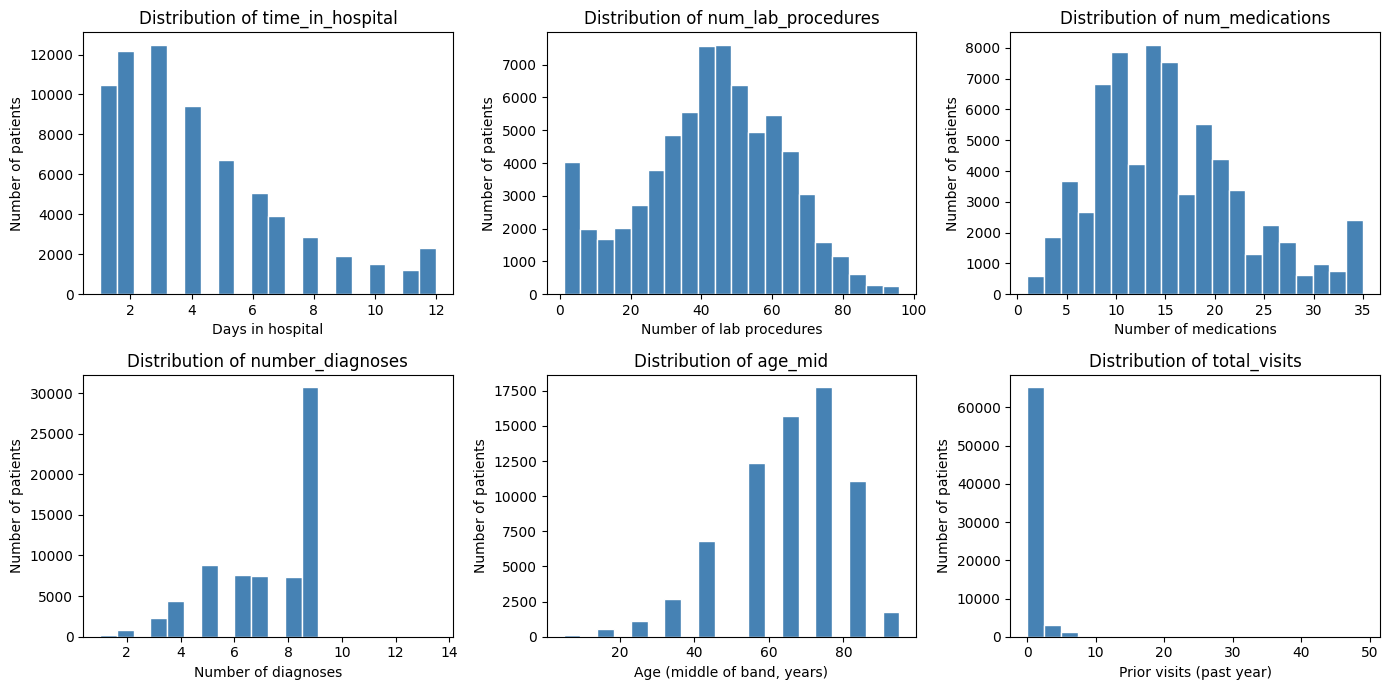

In [52]:
# 6 histograms in a 2 x 3 grid
hist_cols = ["time_in_hospital", "num_lab_procedures", "num_medications", "number_diagnoses", "age_mid", "total_visits"]
x_labels = ["Days in hospital", "Number of lab procedures", "Number of medications",
            "Number of diagnoses", "Age (middle of band, years)", "Prior visits (past year)"]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))

# axes.flatten() turns the 2x3 grid into a simple list of 6 charts
for ax, col, label in zip(axes.flatten(), hist_cols, x_labels):
    ax.hist(df[col], bins=20, color="steelblue", edgecolor="white")
    ax.set_title("Distribution of " + col)
    ax.set_xlabel(label)
    ax.set_ylabel("Number of patients")

plt.tight_layout()
plt.show()

**What we see:**
- `time_in_hospital` and `total_visits` are **right-skewed**: most stays are short and most patients had no prior visits.
- `num_lab_procedures` is roughly bell-shaped, with a peak of very low values (1 procedure).
- `age_mid` is **left-skewed**: most patients are 50 or older.
- The bar at 12 days is caused by IQR capping (all stays of 12-14 days were capped at 12).
- `number_diagnoses` has a tall spike at 9: 30,703 patients (44%) have exactly 9 diagnoses and only 73 have more, which looks like a recording limit of the hospital system.

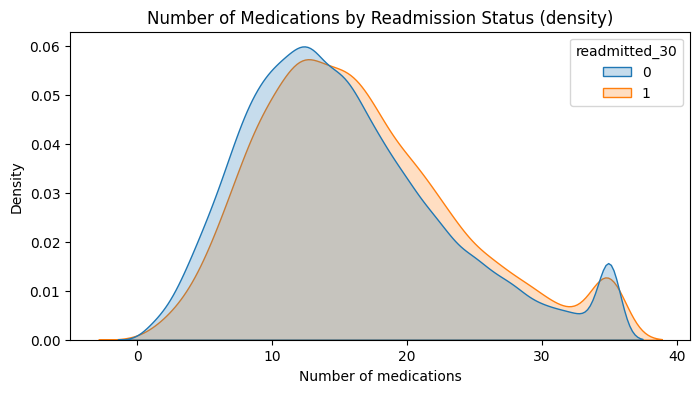

In [53]:
# density plot: number of medications for readmitted vs not readmitted
plt.figure(figsize=(8, 4))
sns.kdeplot(data=df, x="num_medications", hue="readmitted_30", common_norm=False, fill=True)
plt.title("Number of Medications by Readmission Status (density)")
plt.xlabel("Number of medications")
plt.ylabel("Density")
plt.show()

### Step 4: Readmission Rate by Key Groups

The red dashed line is the overall rate (8.97%). Bars above it are higher-risk groups.

#### 4.1 Age band

          count  rate_pct
age                      
[0-10)      153      1.96
[10-20)     534      4.87
[20-30)    1121      7.40
[30-40)    2692      6.98
[40-50)    6828      7.41
[50-60)   12349      7.12
[60-70)   15683      9.00
[70-80)   17748     10.24
[80-90)   11102     10.76
[90-100)   1760      9.55


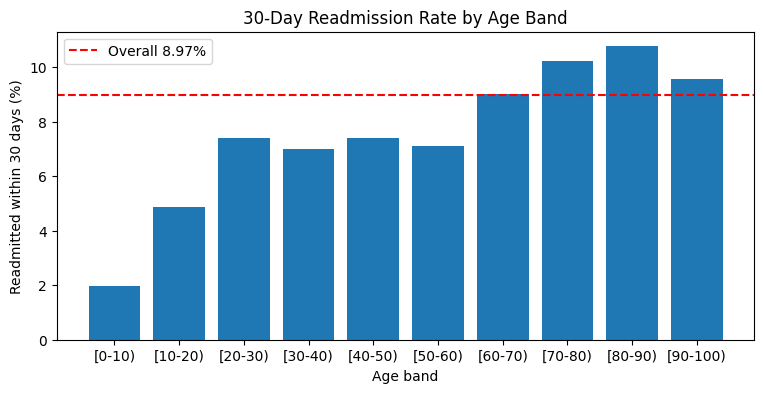

In [54]:
# readmission rate (%) and number of patients for each group
rate = df.groupby("age")["readmitted_30"].agg(["count", "mean"])
rate["rate_pct"] = (rate["mean"] * 100).round(2)
print(rate[["count", "rate_pct"]])

plt.figure(figsize=(9, 4))
plt.bar(rate.index.astype(str), rate["rate_pct"])
plt.axhline(overall_rate, color="red", linestyle="--", label=f"Overall {overall_rate:.2f}%")
plt.title("30-Day Readmission Rate by Age Band")
plt.xlabel("Age band")
plt.ylabel("Readmitted within 30 days (%)")
plt.xticks(rotation=0)
plt.legend()
plt.show()

#### 4.2 Primary diagnosis group

                 count  rate_pct
diag_1_group                    
Injury            4692     10.78
Circulatory      21383      9.67
Diabetes          5748      9.12
Neoplasms         2538      9.06
Genitourinary     3440      8.98
Other            12132      8.98
Musculoskeletal   4064      8.39
Digestive         6487      8.02
Respiratory       9486      7.28


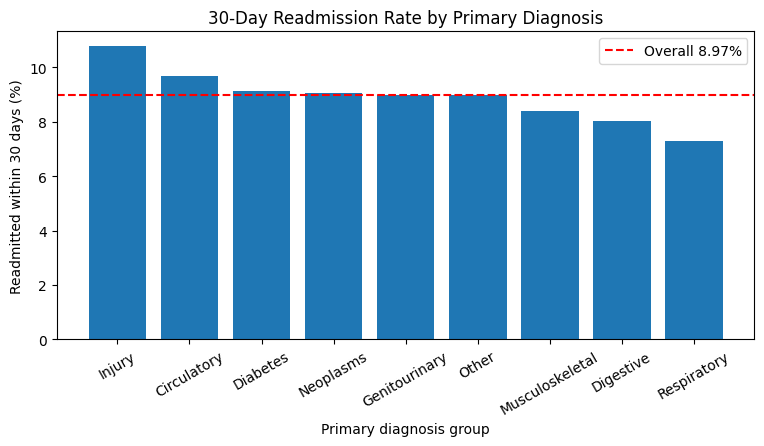

In [55]:
# readmission rate (%) and number of patients for each group
rate = df.groupby("diag_1_group")["readmitted_30"].agg(["count", "mean"])
rate["rate_pct"] = (rate["mean"] * 100).round(2)
rate = rate.sort_values("rate_pct", ascending=False)
print(rate[["count", "rate_pct"]])

plt.figure(figsize=(9, 4))
plt.bar(rate.index.astype(str), rate["rate_pct"])
plt.axhline(overall_rate, color="red", linestyle="--", label=f"Overall {overall_rate:.2f}%")
plt.title("30-Day Readmission Rate by Primary Diagnosis")
plt.xlabel("Primary diagnosis group")
plt.ylabel("Readmitted within 30 days (%)")
plt.xticks(rotation=30)
plt.legend()
plt.show()

#### 4.3 Prior inpatient visits

In [56]:
# group 3 or more prior inpatient visits together (the groups get small)
df["inpatient_band"] = df["number_inpatient"].clip(upper=3).astype(int).astype(str)
df.loc[df["inpatient_band"] == "3", "inpatient_band"] = "3+"

df["inpatient_band"].value_counts()

inpatient_band
0     61779
1      5794
2      1501
3+      896
Name: count, dtype: int64

                count  rate_pct
inpatient_band                 
0               61779      8.12
1                5794     12.89
2                1501     18.52
3+                896     26.45


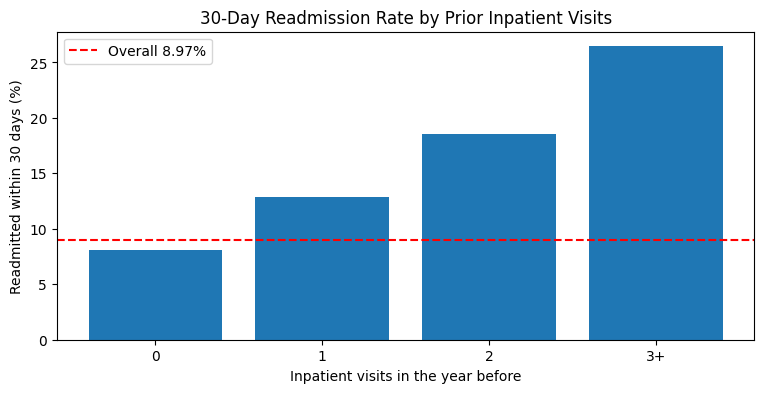

In [57]:
# readmission rate (%) and number of patients for each group
rate = df.groupby("inpatient_band")["readmitted_30"].agg(["count", "mean"])
rate["rate_pct"] = (rate["mean"] * 100).round(2)
print(rate[["count", "rate_pct"]])

plt.figure(figsize=(9, 4))
plt.bar(rate.index.astype(str), rate["rate_pct"])
plt.axhline(overall_rate, color="red", linestyle="--", label=f"Overall {overall_rate:.2f}%")
plt.title("30-Day Readmission Rate by Prior Inpatient Visits")
plt.xlabel("Inpatient visits in the year before")
plt.ylabel("Readmitted within 30 days (%)")
plt.xticks(rotation=0)
plt.legend()
plt.show()

#### 4.4 Time in hospital

                  count  rate_pct
time_in_hospital                 
1.0               10468      6.54
2.0               12178      7.66
3.0               12487      8.18
4.0                9423      8.86
5.0                6697      9.77
6.0                5050     10.89
7.0                3902     11.43
8.0                2842     12.32
9.0                1911     12.30
10.0               1506     12.28
11.0               1188      9.60
12.0               2318     11.56


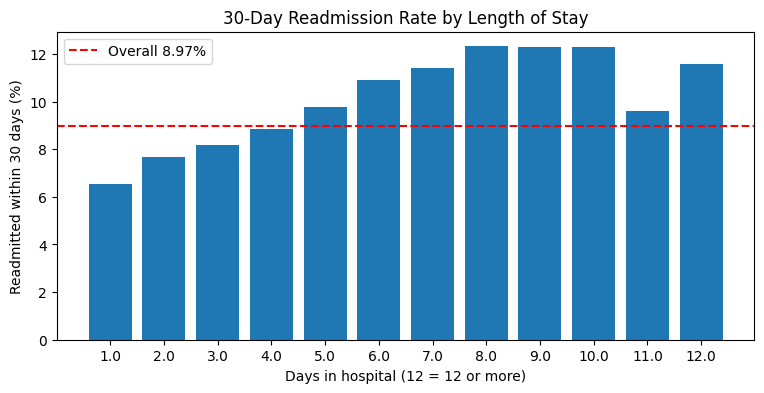

In [58]:
# readmission rate (%) and number of patients for each group
rate = df.groupby("time_in_hospital")["readmitted_30"].agg(["count", "mean"])
rate["rate_pct"] = (rate["mean"] * 100).round(2)
print(rate[["count", "rate_pct"]])

plt.figure(figsize=(9, 4))
plt.bar(rate.index.astype(str), rate["rate_pct"])
plt.axhline(overall_rate, color="red", linestyle="--", label=f"Overall {overall_rate:.2f}%")
plt.title("30-Day Readmission Rate by Length of Stay")
plt.xlabel("Days in hospital (12 = 12 or more)")
plt.ylabel("Readmitted within 30 days (%)")
plt.xticks(rotation=0)
plt.legend()
plt.show()

#### 4.5 HbA1c result

            count  rate_pct
A1Cresult                  
>7           2865      8.59
>8           6239      8.16
Norm         3741      8.63
Not tested  57125      9.10


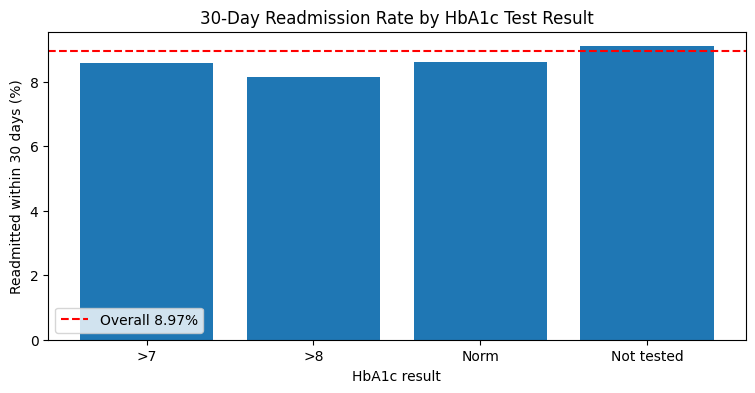

In [59]:
# readmission rate (%) and number of patients for each group
rate = df.groupby("A1Cresult")["readmitted_30"].agg(["count", "mean"])
rate["rate_pct"] = (rate["mean"] * 100).round(2)
print(rate[["count", "rate_pct"]])

plt.figure(figsize=(9, 4))
plt.bar(rate.index.astype(str), rate["rate_pct"])
plt.axhline(overall_rate, color="red", linestyle="--", label=f"Overall {overall_rate:.2f}%")
plt.title("30-Day Readmission Rate by HbA1c Test Result")
plt.xlabel("HbA1c result")
plt.ylabel("Readmitted within 30 days (%)")
plt.xticks(rotation=0)
plt.legend()
plt.show()

#### 4.6 Medication change and diabetes medication

        count  rate_pct
change                 
Ch      31489      9.44
No      38481      8.59


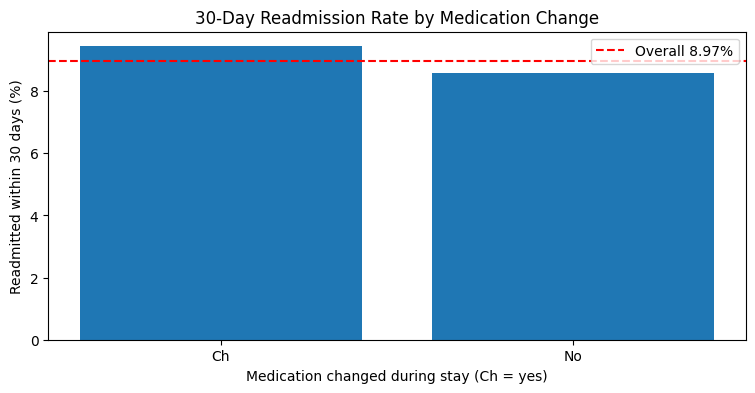

In [60]:
# readmission rate (%) and number of patients for each group
rate = df.groupby("change")["readmitted_30"].agg(["count", "mean"])
rate["rate_pct"] = (rate["mean"] * 100).round(2)
print(rate[["count", "rate_pct"]])

plt.figure(figsize=(9, 4))
plt.bar(rate.index.astype(str), rate["rate_pct"])
plt.axhline(overall_rate, color="red", linestyle="--", label=f"Overall {overall_rate:.2f}%")
plt.title("30-Day Readmission Rate by Medication Change")
plt.xlabel("Medication changed during stay (Ch = yes)")
plt.ylabel("Readmitted within 30 days (%)")
plt.xticks(rotation=0)
plt.legend()
plt.show()

             count  rate_pct
diabetesMed                 
No           16679      7.55
Yes          53291      9.42


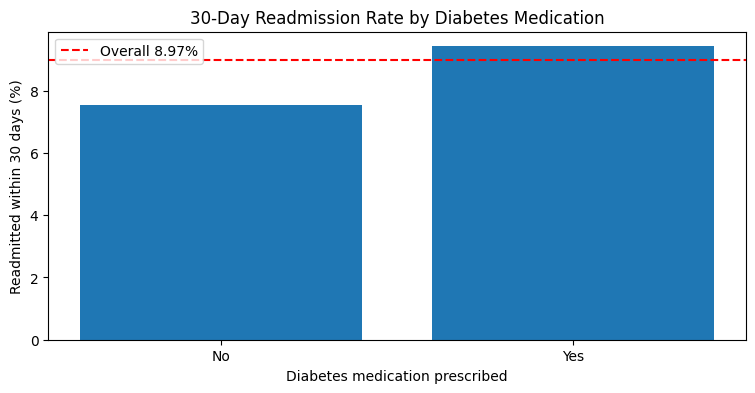

In [61]:
# readmission rate (%) and number of patients for each group
rate = df.groupby("diabetesMed")["readmitted_30"].agg(["count", "mean"])
rate["rate_pct"] = (rate["mean"] * 100).round(2)
print(rate[["count", "rate_pct"]])

plt.figure(figsize=(9, 4))
plt.bar(rate.index.astype(str), rate["rate_pct"])
plt.axhline(overall_rate, color="red", linestyle="--", label=f"Overall {overall_rate:.2f}%")
plt.title("30-Day Readmission Rate by Diabetes Medication")
plt.xlabel("Diabetes medication prescribed")
plt.ylabel("Readmitted within 30 days (%)")
plt.xticks(rotation=0)
plt.legend()
plt.show()

**What we see:**
- **Prior inpatient visits are the strongest signal.** The rate rises from 8.12% (0 visits) to 12.89% (1), 18.52% (2) and 26.45% (3 or more).
- **Length of stay:** the rate climbs from 6.54% (1 day) to about 12% (8-10 days).
- **Age:** patients aged 70-90 have the highest rates (10.24% and 10.76%), and children and young adults the lowest.
- **Diagnosis:** Injury (10.78%) and Circulatory (9.67%) are above average, and Respiratory is lowest (7.28%).
- **HbA1c:** all four groups are close to each other (8.16%-9.10%).
- Patients whose medication was changed (9.44% vs 8.59%) or who are on diabetes medication (9.42% vs 7.55%) are readmitted a bit more often.

### Step 5: Relationships Between Variables

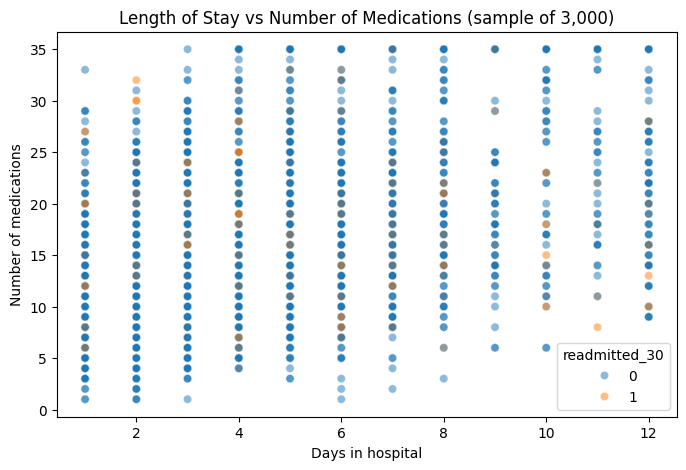

In [62]:
# a random sample of 3,000 patients keeps the scatter plot readable
sample = df.sample(3000, random_state=42)

plt.figure(figsize=(8, 5))
sns.scatterplot(data=sample, x="time_in_hospital", y="num_medications", hue="readmitted_30", alpha=0.5)
plt.title("Length of Stay vs Number of Medications (sample of 3,000)")
plt.xlabel("Days in hospital")
plt.ylabel("Number of medications")
plt.show()

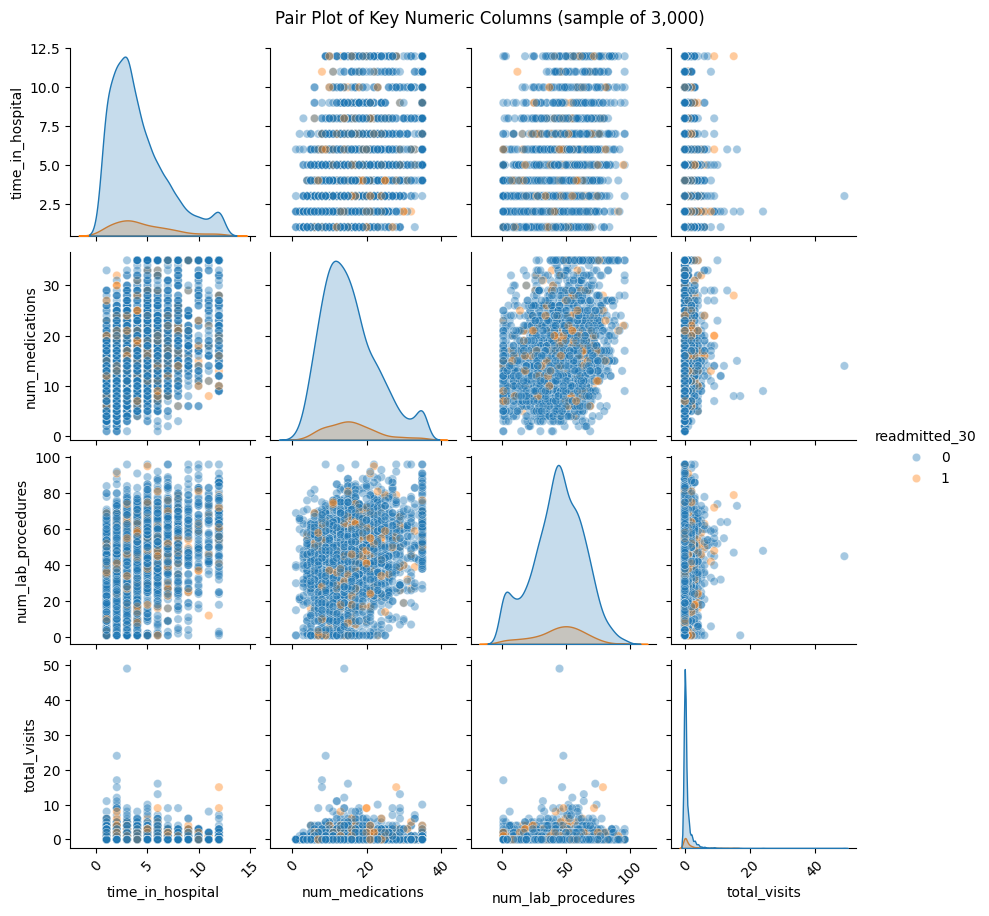

In [63]:
# pair plot: every pair of 4 columns, colored by readmission
pair = sns.pairplot(sample[["time_in_hospital", "num_medications", "num_lab_procedures", "total_visits", "readmitted_30"]],
                    hue="readmitted_30", plot_kws={"alpha": 0.4}, height=2.2)
# turn the x-axis numbers so they do not overlap
for ax in pair.axes.flatten():
    ax.tick_params(axis="x", rotation=45)
pair.figure.suptitle("Pair Plot of Key Numeric Columns (sample of 3,000)", y=1.02)
plt.show()

**What we see:** longer stays come with more medications (an upward cloud of points). Readmitted and non-readmitted patients overlap almost completely in every pair, so no single pair of variables separates the two groups.

### Step 6: Correlation Heatmap

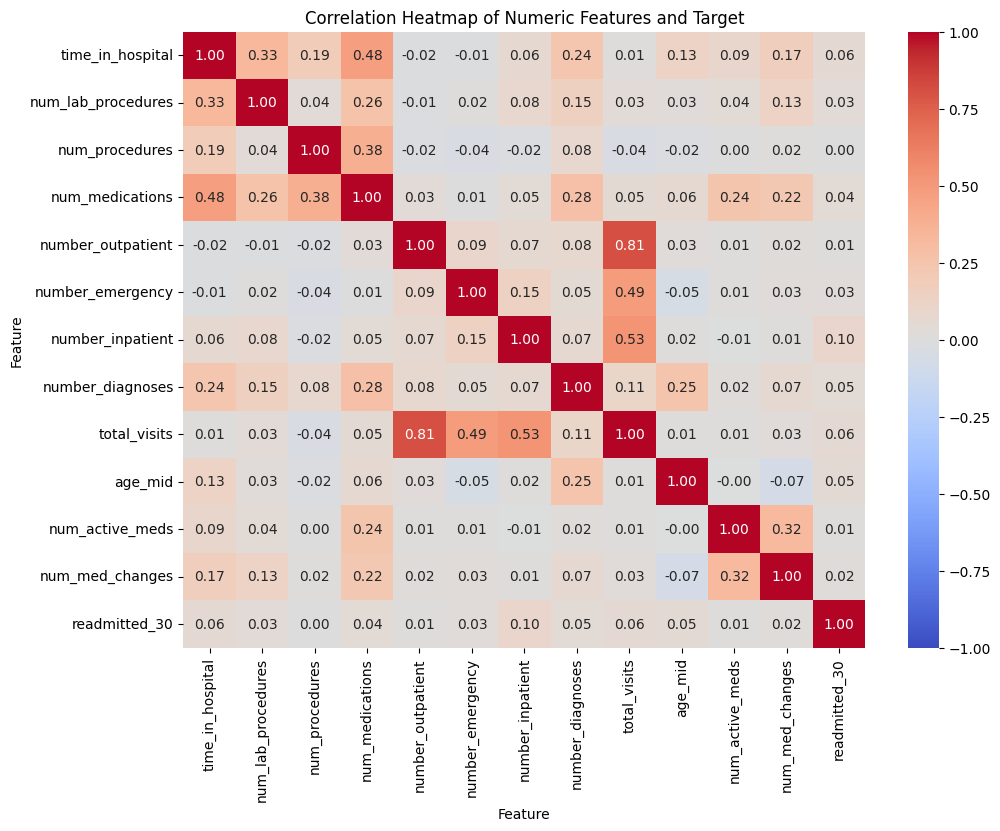

In [64]:
corr = df[numeric_cols + ["readmitted_30"]].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap of Numeric Features and Target")
plt.xlabel("Feature")
plt.ylabel("Feature")
plt.show()

In [65]:
# correlation of every feature with the target, strongest first
corr["readmitted_30"].drop("readmitted_30").sort_values(ascending=False).round(3)

number_inpatient      0.100
total_visits          0.059
time_in_hospital      0.057
age_mid               0.047
number_diagnoses      0.045
num_medications       0.039
num_lab_procedures    0.032
number_emergency      0.028
num_med_changes       0.023
num_active_meds       0.012
number_outpatient     0.009
num_procedures        0.001
Name: readmitted_30, dtype: float64

**What we see:**
- The strongest correlation with the target is `number_inpatient` (0.100), then `total_visits` (0.059) and `time_in_hospital` (0.057). All are weak, so readmission is not driven by any single number.
- Among the features, `num_medications` goes together with `time_in_hospital` (0.48) and `num_procedures` (0.38).
- `total_visits` is correlated with its own parts (outpatient 0.81, inpatient 0.53, emergency 0.49), as expected.

### Step 7: Hypothesis Tests

Significance level: **alpha = 0.05**. If p < 0.05 we reject H0 (no relationship / no difference).

- **Chi-square test** for two categorical variables (is the readmission rate the same in every group?)
- **Welch t-test** for a numeric variable in two groups (is the mean the same for readmitted and not readmitted?). Welch does not assume equal variances.

#### Test 1 (chi-square): Medication change vs readmission
H0: readmission is independent of whether the medication was changed.

In [66]:
table = pd.crosstab(df["change"], df["readmitted_30"])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
print("\nChi-square:", round(chi2, 2), "| dof:", dof, "| p-value:", p)
print("Reject H0" if p < 0.05 else "Do not reject H0")

readmitted_30      0     1
change                    
Ch             28518  2971
No             35175  3306

Chi-square: 15.0 | dof: 1 | p-value: 0.00010776426381830976
Reject H0


**Interpretation:** p = 0.0001 < 0.05, so a medication change is linked to readmission. Changed patients are readmitted more often (9.44% vs 8.59%).

#### Test 2 (chi-square): Primary diagnosis group vs readmission
H0: readmission is independent of the primary diagnosis group.

In [67]:
table = pd.crosstab(df["diag_1_group"], df["readmitted_30"])

chi2, p, dof, expected = chi2_contingency(table)
print("Chi-square:", round(chi2, 2), "| dof:", dof, "| p-value:", p)
print("Reject H0" if p < 0.05 else "Do not reject H0")

Chi-square: 73.7 | dof: 8 | p-value: 8.984853507485246e-13
Reject H0


**Interpretation:** p ≈ 9e-13 < 0.05, so readmission rates really differ by diagnosis, from 7.28% (Respiratory) to 10.78% (Injury).

#### Test 3 (chi-square): HbA1c result vs readmission
H0: readmission is independent of the HbA1c test result.

In [68]:
table = pd.crosstab(df["A1Cresult"], df["readmitted_30"])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
print("\nChi-square:", round(chi2, 2), "| dof:", dof, "| p-value:", p)
print("Reject H0" if p < 0.05 else "Do not reject H0")

readmitted_30      0     1
A1Cresult                 
>7              2619   246
>8              5730   509
Norm            3418   323
Not tested     51926  5199

Chi-square: 7.27 | dof: 3 | p-value: 0.06381865444870938
Do not reject H0


**Interpretation:** p = 0.064 > 0.05, so we **cannot** reject H0. In this data the HbA1c result (or not testing at all) shows no significant link to 30-day readmission.

#### Test 4 (t-test): Length of stay, readmitted vs not
H0: mean `time_in_hospital` is the same for both groups.

In [69]:
readmitted = df.loc[df["readmitted_30"] == 1, "time_in_hospital"]
not_readmitted = df.loc[df["readmitted_30"] == 0, "time_in_hospital"]

print("Mean days, readmitted:", round(readmitted.mean(), 3))
print("Mean days, not readmitted:", round(not_readmitted.mean(), 3))

t_stat, p = ttest_ind(readmitted, not_readmitted, equal_var=False)
print("\nt-statistic:", round(t_stat, 2), "| p-value:", p)
print("Reject H0" if p < 0.05 else "Do not reject H0")

Mean days, readmitted: 4.761
Mean days, not readmitted: 4.193

t-statistic: 14.55 | p-value: 2.568817065064052e-47
Reject H0


**Interpretation:** p ≈ 3e-47 < 0.05. Readmitted patients stayed longer on average (4.76 vs 4.19 days).

#### Test 5 (t-test): Prior inpatient visits, readmitted vs not
H0: mean `number_inpatient` is the same for both groups.

In [70]:
readmitted = df.loc[df["readmitted_30"] == 1, "number_inpatient"]
not_readmitted = df.loc[df["readmitted_30"] == 0, "number_inpatient"]

print("Mean prior inpatient visits, readmitted:", round(readmitted.mean(), 3))
print("Mean prior inpatient visits, not readmitted:", round(not_readmitted.mean(), 3))

t_stat, p = ttest_ind(readmitted, not_readmitted, equal_var=False)
print("\nt-statistic:", round(t_stat, 2), "| p-value:", p)
print("Reject H0" if p < 0.05 else "Do not reject H0")

Mean prior inpatient visits, readmitted: 0.369
Mean prior inpatient visits, not readmitted: 0.157

t-statistic: 16.8 | p-value: 4.655913786179672e-62
Reject H0


**Interpretation:** p ≈ 5e-62 < 0.05, the strongest result of all. Readmitted patients had more than twice as many prior inpatient visits (0.369 vs 0.157).

**A note on large samples:** with ~70,000 patients even small differences become "significant". A p-value says a difference is real, not that it is big. That is why we also compare the rates and means above.

### Step 8: Key Insights

1. **History predicts the future.** Prior inpatient visits are the strongest single signal. The rate rises from 8.12% (0 visits) to 26.45% (3+ visits).
2. **Longer stays mean higher risk.** The rate rises from 6.54% (1 day) to about 12% (8-10 days). Readmitted patients stayed 4.76 vs 4.19 days on average.
3. **Older patients (70-90) are at higher risk** (10.24%-10.76%) than younger adults (about 7%).
4. **Diagnosis matters:** Injury and Circulatory are above average; Respiratory is lowest.
5. **HbA1c testing showed no significant effect** (p = 0.064).
6. **All correlations with the target are weak** (max 0.100). A model must combine many features, and readmission will be hard to predict precisely.

These insights are summarised in `../docs/insights.md`.

## Part 4: Modeling

**Input:** `model_df` from Part 2 (69,970 patients, 139 features + target `readmitted_30`, already encoded and scaled)

**Models:** Logistic Regression and Decision Tree

**Steps:**
1. Split into train / test
2. Baseline: what accuracy do we get by always guessing "not readmitted"?
3. Handle class imbalance
4. Train Logistic Regression
5. Train Decision Tree
6. Evaluate: accuracy, precision, recall, ROC-AUC, confusion matrix, ROC curve
7. Top features
8. Save results for the dashboard

### Step 1: Split

In [71]:
# model_df is the encoded and scaled table from Part 2
print("Shape:", model_df.shape)

Shape: (69970, 140)


In [72]:
# X = features (everything except the target), y = target
X = model_df.drop(columns=["readmitted_30"])
y = model_df["readmitted_30"]

# 80% train, 20% test
# stratify=y keeps the same share of readmitted patients (~9%) in both parts
# random_state=42 makes the split the same every time we run the notebook
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print("Train:", X_train.shape, "| readmitted %:", round(y_train.mean() * 100, 2))
print("Test: ", X_test.shape, "| readmitted %:", round(y_test.mean() * 100, 2))

Train: (55976, 139) | readmitted %: 8.97
Test:  (13994, 139) | readmitted %: 8.97


### Step 2: Baseline

Only ~9% of patients are readmitted. A "model" that always says **0 (not readmitted)** is already ~91% accurate, but it finds **zero** readmitted patients. Accuracy alone is therefore misleading. **Recall** (how many real readmissions we catch) and **ROC-AUC** (how well the model ranks risky patients above safe ones) matter more.

In [73]:
# predict 0 for every test patient
baseline_pred = np.zeros(len(y_test))

print("Baseline accuracy:", round(accuracy_score(y_test, baseline_pred), 4))
print("Baseline recall:  ", recall_score(y_test, baseline_pred))

Baseline accuracy: 0.9103
Baseline recall:   0.0


### Step 3: Handle Class Imbalance

We use `class_weight="balanced"`. It tells the model that a mistake on a readmitted patient (the rare class) costs about **10 times** more than a mistake on a non-readmitted one. The weight is `total / (2 * class count)`. No rows are added or removed; the model just pays more attention to the rare class.

In [74]:
# the weights that class_weight="balanced" will use
n = len(y_train)
print("Weight for class 0:", round(n / (2 * (y_train == 0).sum()), 3))
print("Weight for class 1:", round(n / (2 * (y_train == 1).sum()), 3))

Weight for class 0: 0.549
Weight for class 1: 5.573


### Step 4: Logistic Regression

In [75]:
# max_iter=1000 gives the solver enough steps to finish with 139 features
log_model = LogisticRegression(max_iter=1000, class_weight="balanced")
log_model.fit(X_train, y_train)

# predicted class (0/1) and predicted probability of readmission
log_pred = log_model.predict(X_test)
log_prob = log_model.predict_proba(X_test)[:, 1]

### Step 5: Decision Tree

`max_depth=5` keeps the tree small. A deep tree memorises the training data (overfitting) and is impossible to read.

In [76]:
tree_model = DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42)
tree_model.fit(X_train, y_train)

tree_pred = tree_model.predict(X_test)
tree_prob = tree_model.predict_proba(X_test)[:, 1]

### Step 6: Evaluate

- **Accuracy:** share of all predictions that are correct
- **Precision:** of the patients we flagged as readmitted, how many really were
- **Recall:** of the patients really readmitted, how many we flagged
- **ROC-AUC:** 0.5 = random guessing, 1.0 = perfect ranking

In [77]:
# one row per model
results = pd.DataFrame({
    "model": ["Logistic Regression", "Decision Tree"],
    "accuracy": [accuracy_score(y_test, log_pred), accuracy_score(y_test, tree_pred)],
    "precision": [precision_score(y_test, log_pred), precision_score(y_test, tree_pred)],
    "recall": [recall_score(y_test, log_pred), recall_score(y_test, tree_pred)],
    "roc_auc": [roc_auc_score(y_test, log_prob), roc_auc_score(y_test, tree_prob)],
})

results.round(4)

,model,accuracy,precision,recall,roc_auc
0,Logistic Regression,0.6581,0.1388,0.5402,0.6457
1,Decision Tree,0.6100,0.1277,0.5745,0.6187


In [78]:
print("Logistic Regression")
print(classification_report(y_test, log_pred, digits=3))
print("Decision Tree")
print(classification_report(y_test, tree_pred, digits=3))

Logistic Regression
              precision    recall  f1-score   support

           0      0.937     0.670     0.781     12739
           1      0.139     0.540     0.221      1255

    accuracy                          0.658     13994
   macro avg      0.538     0.605     0.501     13994
weighted avg      0.865     0.658     0.731     13994

Decision Tree
              precision    recall  f1-score   support

           0      0.936     0.614     0.741     12739
           1      0.128     0.575     0.209      1255

    accuracy                          0.610     13994
   macro avg      0.532     0.594     0.475     13994
weighted avg      0.864     0.610     0.694     13994



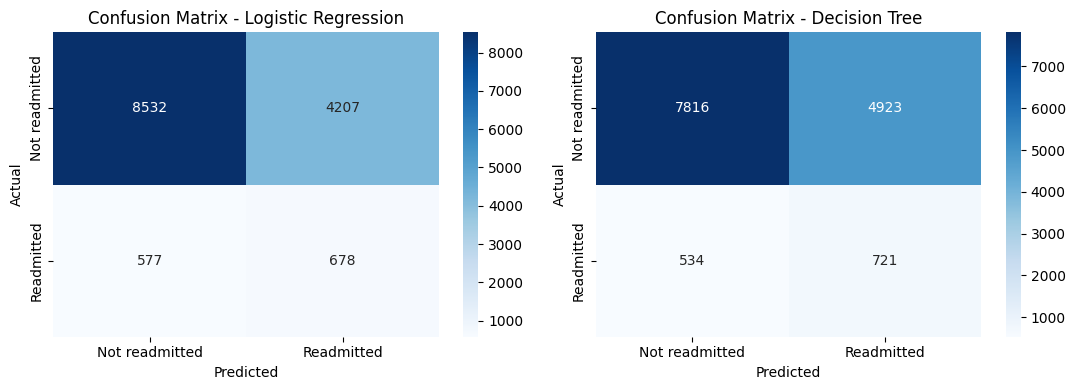

In [79]:
# confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, pred, name in zip(axes, [log_pred, tree_pred], ["Logistic Regression", "Decision Tree"]):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Not readmitted", "Readmitted"], yticklabels=["Not readmitted", "Readmitted"])
    ax.set_title("Confusion Matrix - " + name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

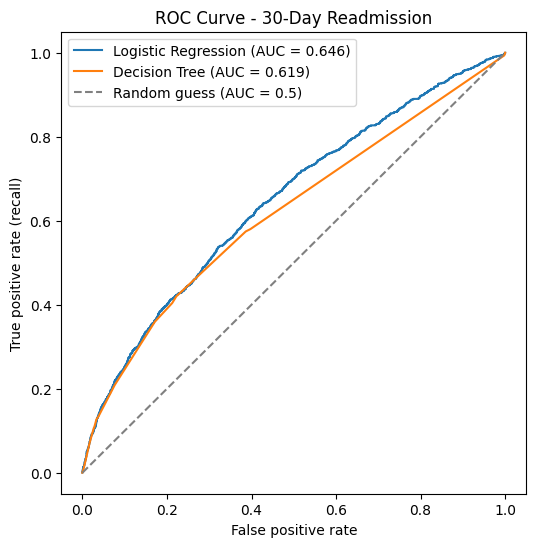

In [80]:
# ROC curve: true positive rate vs false positive rate at every threshold
log_fpr, log_tpr, _ = roc_curve(y_test, log_prob)
tree_fpr, tree_tpr, _ = roc_curve(y_test, tree_prob)

plt.figure(figsize=(6, 6))
plt.plot(log_fpr, log_tpr, label=f"Logistic Regression (AUC = {roc_auc_score(y_test, log_prob):.3f})")
plt.plot(tree_fpr, tree_tpr, label=f"Decision Tree (AUC = {roc_auc_score(y_test, tree_prob):.3f})")
plt.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Random guess (AUC = 0.5)")
plt.title("ROC Curve - 30-Day Readmission")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.legend()
plt.show()

**What we see:**
- **Logistic Regression is better on every ranking measure:** ROC-AUC 0.646 vs 0.619.
- Both models catch more than half of the real readmissions (recall 0.540 and 0.575), far better than the baseline's 0.
- **Precision is low** (0.139 and 0.128). Only about 1 in 7-8 flagged patients is really readmitted, so many patients get flagged "just in case".
- Accuracy (0.658 and 0.610) is below the baseline's 0.91, because the models now flag many patients to catch the rare readmissions. This is the expected trade-off.
- An AUC around 0.65 is typical for this dataset. Readmission depends on things not recorded here (support at home, follow-up care), so it is hard to predict.

### Step 7: Top Features

#### Logistic Regression coefficients
Because the numeric features are scaled, the coefficient size shows importance. **Positive = raises** readmission risk, **negative = lowers** it.

In [81]:
coef = pd.DataFrame({"feature": X.columns, "coefficient": log_model.coef_[0]})
coef["abs_coef"] = coef["coefficient"].abs()

top_log = coef.sort_values("abs_coef", ascending=False).head(10)
top_log[["feature", "coefficient"]].round(3)

,feature,coefficient
105,discharge_disposition_id_15,2.038
115,discharge_disposition_id_28,1.746
53,payer_code_SI,-1.729
23,tolazamide,-1.717
110,discharge_disposition_id_22,1.567
101,admission_type_id_7,-1.446
111,discharge_disposition_id_23,-1.416
118,discharge_disposition_id_5,1.206
104,discharge_disposition_id_12,1.104
122,discharge_disposition_id_9,0.756


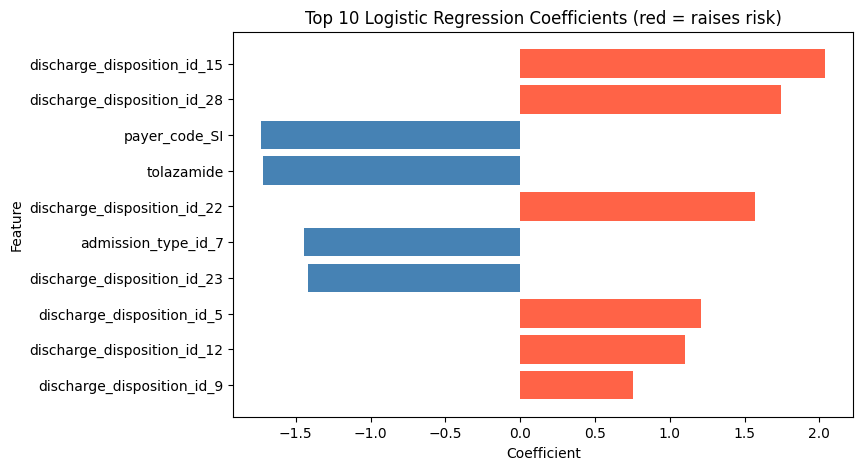

In [82]:
plt.figure(figsize=(8, 5))
colors = ["tomato" if c > 0 else "steelblue" for c in top_log["coefficient"]]
plt.barh(top_log["feature"], top_log["coefficient"], color=colors)
plt.gca().invert_yaxis()     # biggest at the top
plt.title("Top 10 Logistic Regression Coefficients (red = raises risk)")
plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.show()

**Careful reading:** most of the biggest coefficients belong to **very rare categories**. For example, discharge code 15 (swing bed) has 40 patients, 28 (psychiatric hospital) 90, `payer_code_SI` 37, `tolazamide` 30, and discharge code 12 only 2. With so few patients, one or two readmissions push the coefficient far up or down, so these values are **unstable** and should not be read as the main drivers.

The more reliable signals are the categories with many patients: discharge to a **rehab facility (22, 1,409 patients, 26.33% readmitted)** and to **another inpatient institution (5, 913 patients, 20.59%)**. Both raise risk.

To compare the numeric features fairly (they are all scaled, so 1 unit = 1 standard deviation), here are their coefficients:

In [83]:
numeric_features = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
                    "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses",
                    "total_visits", "age_mid", "num_active_meds", "num_med_changes"]

coef.loc[coef["feature"].isin(numeric_features), ["feature", "coefficient"]].sort_values("coefficient", ascending=False).round(3)

,feature,coefficient
7,number_inpatient,0.172
8,number_diagnoses,0.087
33,age_mid,0.076
32,total_visits,0.064
1,time_in_hospital,0.063
6,number_emergency,0.058
35,num_med_changes,0.039
4,num_medications,0.022
2,num_lab_procedures,0.013
3,num_procedures,-0.008


**What we see:** among numeric features, **`number_inpatient` raises risk the most** (+0.172), then `number_diagnoses`, `age_mid`, `total_visits` and `time_in_hospital`. This matches the EDA. `num_active_meds` is negative (-0.286), but it is built from the 21 medicine columns that are also in the model, so its coefficient is mixed up with theirs (multicollinearity) and should not be read on its own.

#### Decision Tree feature importance
Importance = how much each feature helped the tree split patients into purer groups (all values add up to 1).

In [84]:
importance = pd.DataFrame({"feature": X.columns, "importance": tree_model.feature_importances_})

top_tree = importance.sort_values("importance", ascending=False).head(10)
top_tree.round(4)

,feature,importance
7,number_inpatient,0.3192
110,discharge_disposition_id_22,0.2206
116,discharge_disposition_id_3,0.1707
118,discharge_disposition_id_5,0.0908
1,time_in_hospital,0.0889
47,payer_code_MC,0.0268
109,discharge_disposition_id_2,0.0184
4,num_medications,0.0112
79,diag_1_group_Respiratory,0.0101
46,payer_code_HM,0.0096


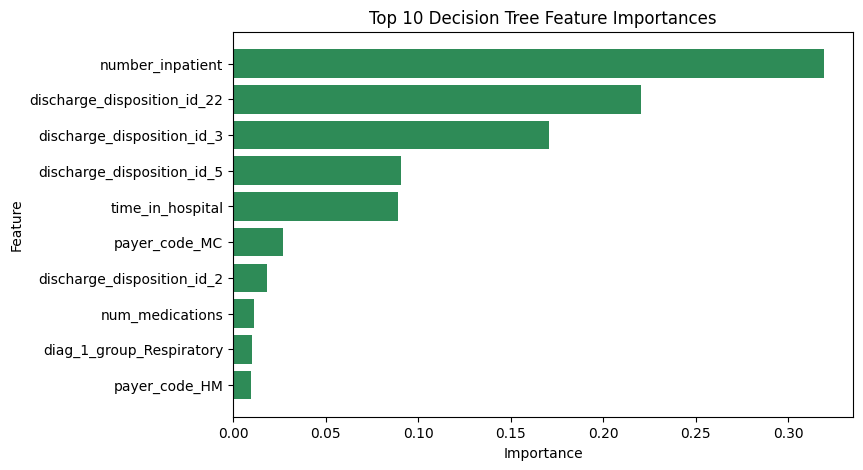

In [85]:
plt.figure(figsize=(8, 5))
plt.barh(top_tree["feature"], top_tree["importance"], color="seagreen")
plt.gca().invert_yaxis()
plt.title("Top 10 Decision Tree Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

**What we see:** the tree agrees with the EDA. **`number_inpatient` (prior inpatient visits) is the most important feature** (0.319), followed by discharge to a rehab facility (22), a skilled nursing facility (3), another inpatient institution (5) and `time_in_hospital`. Patients discharged to another care facility are usually sicker, which explains why they come back more often.

### Step 8: Save Results for the Dashboard

In [86]:
# model metrics (one row per model)
results.round(4).to_csv(f"{DATA_DIR}/model_metrics.csv", index=False)

# top 10 features of each model in one table
top_log_out = top_log[["feature", "coefficient"]].rename(columns={"coefficient": "value"})
top_log_out["model"] = "Logistic Regression (coefficient)"
top_tree_out = top_tree.rename(columns={"importance": "value"})
top_tree_out["model"] = "Decision Tree (importance)"

top_features = pd.concat([top_log_out, top_tree_out])[["model", "feature", "value"]].round(4)
top_features.to_csv(f"{DATA_DIR}/top_features.csv", index=False)

print("Saved ../data/model_metrics.csv and ../data/top_features.csv")

Saved ../data/model_metrics.csv and ../data/top_features.csv


## Part 5: Dashboard Prep

Export tidy CSVs for Power BI into `../data/powerbi/`.

**Inputs (all still in memory):** `df` (Part 2), the lookup tables (Setup), `results` and `top_features` (Part 4)

"Tidy" means: **one row per observation, one column per variable, one value per cell.** Power BI works best with tables like this.

| File | One row = | Used on page |
|------|-----------|--------------|
| `patients.csv` | one patient | 1, 2 |
| `readmission_by_group.csv` | one group of one variable (long format) | 2 |
| `model_metrics.csv` | one model x one metric (long format) | 3 |
| `top_features.csv` | one model x one feature | 3 |

The plan for the 3 dashboard pages is in `../docs/dashboard_plan.md`.

**Steps:**
1. Start from the cleaned data
2. Replace ID codes with their descriptions
3. Add band columns for charts
4. Export `patients.csv`
5. Export `readmission_by_group.csv`
6. Export model results
7. Check the exported files

### Step 1: Start from the Cleaned Data

In [87]:
# df is the cleaned readable table from Part 2 (the powerbi folder was created in Setup)
print("Patients:", len(df))

Patients: 69970


### Step 2: Replace ID Codes with Their Descriptions

Power BI users should see "Emergency", not "1". The three lookup tables come from `IDS_mapping.csv` (same split as in `sql/load_data.py`).

In [88]:

# rename the description column so each one has its own name after merging
admission_type = admission_type_map.rename(columns={"description": "admission_type"})
discharge = discharge_map.rename(columns={"description": "discharge_disposition"})
admission_source = admission_source_map.rename(columns={"description": "admission_source"})

# remove extra spaces at the start of some descriptions
admission_source["admission_source"] = admission_source["admission_source"].str.strip()

# left merge = keep every patient, add the matching description
df = df.merge(admission_type, on="admission_type_id", how="left")
df = df.merge(discharge, on="discharge_disposition_id", how="left")
df = df.merge(admission_source, on="admission_source_id", how="left")

# the file writes NULL for some codes, which pandas reads as missing
for col in ["admission_type", "discharge_disposition", "admission_source"]:
    df[col] = df[col].fillna("Unknown")

df[["admission_type_id", "admission_type", "discharge_disposition_id", "discharge_disposition"]].head()

,admission_type_id,admission_type,discharge_disposition_id,discharge_disposition
0,2,Urgent,1,Discharged to home
1,3,Elective,3,Discharged/transferred to SNF
2,1,Emergency,1,Discharged to home
3,1,Emergency,1,Discharged to home
4,2,Urgent,1,Discharged to home


### Step 3: Add Band Columns for Charts

Small bands are easier to chart than raw numbers.

In [89]:
# prior inpatient visits: 0, 1, 2, 3+
df["inpatient_band"] = df["number_inpatient"].clip(upper=3).astype(int).astype(str)
df.loc[df["inpatient_band"] == "3", "inpatient_band"] = "3+"

# length of stay band
df["stay_band"] = pd.cut(df["time_in_hospital"], bins=[0, 3, 6, 9, 12],
                         labels=["1-3 days", "4-6 days", "7-9 days", "10-12 days"])

df[["number_inpatient", "inpatient_band", "time_in_hospital", "stay_band"]].head()

,number_inpatient,inpatient_band,time_in_hospital,stay_band
0,0.0,0,12.0,10-12 days
1,0.0,0,12.0,10-12 days
2,0.0,0,1.0,1-3 days
3,0.0,0,9.0,7-9 days
4,0.0,0,3.0,1-3 days


### Step 4: Export `patients.csv`

In [90]:
patient_cols = ["encounter_id", "patient_nbr", "race", "gender", "age", "age_mid",
                "admission_type", "discharge_disposition", "admission_source", "medical_specialty",
                "time_in_hospital", "stay_band", "num_lab_procedures", "num_procedures", "num_medications",
                "number_outpatient", "number_emergency", "number_inpatient", "inpatient_band", "total_visits",
                "number_diagnoses", "diag_1_group", "diag_2_group", "diag_3_group",
                "A1Cresult", "insulin", "change", "diabetesMed", "num_active_meds", "num_med_changes",
                "readmitted", "readmitted_30"]

patients = df[patient_cols]
patients.to_csv(f"{DATA_DIR}/powerbi/patients.csv", index=False)

print("patients.csv:", patients.shape)

patients.csv: (69970, 32)


### Step 5: Export `readmission_by_group.csv` (long format)

One table holding the readmission rate for every group of several variables. In Power BI, filter on `variable` to show one chart per variable.

In [91]:
group_vars = ["age", "gender", "race", "diag_1_group", "inpatient_band", "stay_band",
              "A1Cresult", "change", "diabetesMed", "admission_type", "discharge_disposition", "medical_specialty"]

parts = []
for var in group_vars:
    g = df.groupby(var, observed=True)["readmitted_30"].agg(["count", "sum"]).reset_index()
    g.columns = ["group", "patients", "readmitted_30"]
    g["variable"] = var
    g["readmission_rate_pct"] = (g["readmitted_30"] / g["patients"] * 100).round(2)
    parts.append(g)

by_group = pd.concat(parts)[["variable", "group", "patients", "readmitted_30", "readmission_rate_pct"]]
by_group.to_csv(f"{DATA_DIR}/powerbi/readmission_by_group.csv", index=False)

print("readmission_by_group.csv:", by_group.shape)
by_group.loc[by_group["variable"] == "inpatient_band"]

readmission_by_group.csv: (84, 5)


,variable,group,patients,readmitted_30,readmission_rate_pct
0,inpatient_band,0,61779,5015,8.12
1,inpatient_band,1,5794,747,12.89
2,inpatient_band,2,1501,278,18.52
3,inpatient_band,3+,896,237,26.45


### Step 6: Export Model Results (long format)

In [92]:
# model results from Part 4 are still in memory (results, top_features)
metrics = results.round(4)

# wide (one column per metric) -> long (one row per model x metric)
metrics_long = metrics.melt(id_vars="model", var_name="metric", value_name="value")
metrics_long.to_csv(f"{DATA_DIR}/powerbi/model_metrics.csv", index=False)

top_features.to_csv(f"{DATA_DIR}/powerbi/top_features.csv", index=False)

metrics_long

,model,metric,value
0,Logistic Regression,accuracy,0.6581
1,Decision Tree,accuracy,0.6100
2,Logistic Regression,precision,0.1388
3,Decision Tree,precision,0.1277
4,Logistic Regression,recall,0.5402
5,Decision Tree,recall,0.5745
6,Logistic Regression,roc_auc,0.6457
7,Decision Tree,roc_auc,0.6187


### Step 7: Check the Exported Files

In [93]:
for file in sorted(os.listdir(f"{DATA_DIR}/powerbi")):
    t = pd.read_csv(f"{DATA_DIR}/powerbi/" + file)
    print(file, "| rows:", len(t), "| columns:", t.shape[1], "| missing values:", t.isna().sum().sum())

model_metrics.csv | rows: 8 | columns: 3 | missing values: 0


patients.csv | rows: 69970 | columns: 32 | missing values: 0
readmission_by_group.csv | rows: 84 | columns: 5 | missing values: 0
top_features.csv | rows: 20 | columns: 3 | missing values: 0
